# Лабораторная работа к главе 3. Аппроксимация функций

**Учебное пособие «Нейронные сети для инженеров»**

*Нейросетевой аппроксиматор обратного отображения «отсчёты импульса → параметры» и его сравнение с классическими методами*

---

**Цель работы.** Построить нейросетевой аппроксиматор обратного отображения «отсчёты гауссова импульса — его параметры», сравнить его с аналитическим восстановлением и с нелинейным методом наименьших квадратов (МНК) и исследовать границы применимости модели: зависимость от объёма данных, чувствительность к шуму, поведение при отсутствии закономерности в данных.

Тетрадь повторяет порядок выполнения из п. 3.4.7 и сопровождает основной Engee-скрипт `inverse_engee.jl`. Расчётное ядро написано на NumPy без специализированных нейросетевых библиотек: прямой проход, обратное распространение ошибки и метод Adam выписаны явно, как в листингах 3.3 и 3.4.

| Шаг | Содержание | Раздел главы |
|---|---|---|
| 1 | Прямая задача: форма импульса и сетка отсчётов | 3.4.1 |
| 2 | Фиксированные базисы: Тейлор, МНК, гармоники, ReLU-сплайн | 3.2–3.3 |
| 3 | Общие данные и аналитическое восстановление | 3.4.2–3.4.3 |
| 4 | Сеть 21–21–15–3: обучение и отбор по валидации | 3.4.3–3.4.5 |
| 5 | Контрольный пример $(0{,}2;\,0{,}8;\,0{,}7)$ | 3.4.5 |
| 6 | Объём обучающей выборки и размер скрытых слоёв | 3.4.7 |
| 7 | Шум: четыре режима, смещённая и центрированная помеха | 3.4.6 |
| 8 | Случайные цели: запоминание и обобщение | 3.4.6 |
| 9 | Дополнительное задание: ограниченный нелинейный МНК | 3.4.2, 3.4.7 |

## 0. Обозначения

Каждое обозначение вводится при первом использовании; ниже они собраны вместе для удобства. Нумерация формул совпадает с главой 3.

| Символ | Смысл |
|---|---|
| $x$ | безразмерный аргумент импульса (координата или время), $x\in[0,1]$ |
| $x_j=0{,}05\,j$, $j=0,\dots,20$ | узлы сетки отсчётов; всего 21 узел, включая оба конца отрезка |
| $C$ | амплитуда импульса, $C>0$ |
| $A$ | положение максимума импульса |
| $S$ | масштаб ширины, $S>0$; в показателе экспоненты стоит $S$, а не $S^2$, поэтому $S=2\sigma^2$, где $\sigma$ — стандартное отклонение в обычной гауссовой записи |
| $\mathbf p=(y(x_0),\dots,y(x_{20}))^{\mathsf T}$ | входной вектор сети — 21 отсчёт импульса |
| $\mathbf t=(C,A,S)^{\mathsf T}$, $\hat{\mathbf t}$ | целевой вектор (эталон) и прогноз сети |
| $M$ | число примеров в выборке; $\mathbf P$ ($21\times M$) и $\mathbf T$ ($3\times M$) — матрицы входов и целей, пример по столбцу |
| $\mu_j,\ s_j$ | среднее и стандартное отклонение $j$-го входного канала, вычисленные **только** по обучающей части |
| $\tilde p_j,\ \tilde t_q$ | нормированные вход и цель, формула (3.37); $q=1,2,3$ — номер выхода |
| $\mathbf W^{(l)},\ \mathbf b^{(l)}$ | матрица весов и вектор смещений слоя $l=1,2,3$ |
| $\mathbf h^{(l)}$ | выход скрытого слоя $l$ |
| $\varphi(u)=1/(1+e^{-u})$ | логистическая сигмоида, $u$ — взвешенная сумма на входе нейрона |
| $L$ | критерий обучения — MSE по нормированным выходам, формула (3.38); $B$ — размер пакета |
| $\eta,\ \beta_1,\ \beta_2,\ \kappa$ | шаг Adam, коэффициенты усреднения первого и второго моментов и численная добавка в знаменателе (в тексте главы — «численная добавка $10^{-8}$»; здесь обозначена $\kappa$, чтобы не путать с шумом $\varepsilon$) |
| $q_0,q_1,q_2$ | коэффициенты квадратичной модели логарифма сигнала, формула (3.34) |
| $\varepsilon$, $\delta$ | аддитивная помеха в отсчётах и ширина интервала её равномерного распределения |
| RMSE, MAE, Max | корень из средней квадратичной ошибки, средняя абсолютная ошибка, максимальная абсолютная ошибка, формула (3.4) |

### Подготовка вычислений

Все рисунки строятся векторной графикой (SVG) в чёрно-белой гамме с серошкальными заливками; классы и кривые различаются формой маркеров и типом штриха, а не цветом. Для подписей и формул используется математический шрифт STIX, совместимый по начертанию с Times New Roman. Каждый рисунок дополнительно сохраняется в каталог `figures/` в форматах SVG и PDF для вставки в отчёт.

In [24]:
import os, time, pathlib, copy
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%config InlineBackend.figure_formats = ['svg']

mpl.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 9.5,
    "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=["black", "0.35", "0.6"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "lines.linewidth": 1.3,
    "image.cmap": "gray",
    "figure.dpi": 110,
    "axes.formatter.use_locale": False,
})

FIG = pathlib.Path("figures"); FIG.mkdir(exist_ok=True)
DATA = pathlib.Path("data");   DATA.mkdir(exist_ok=True)

class CommaFormatter(mpl.ticker.ScalarFormatter):
    # Десятичная запятая на осях, как принято в русских текстах.
    def __call__(self, v, pos=None):
        return super().__call__(v, pos).replace(".", ",")

def savefig(fig, name):
    for a in fig.axes:
        if a.get_xscale() == "linear": a.xaxis.set_major_formatter(CommaFormatter())
        if a.get_yscale() == "linear": a.yaxis.set_major_formatter(CommaFormatter())
    for ext in ("svg", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")

def comma(v, nd=5):
    # Число с десятичной запятой — для таблиц в русском отчёте.
    return f"{v:.{nd}f}".replace(".", ",")

np.set_printoptions(precision=5, suppress=True)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| Matplotlib", mpl.__version__)

NumPy 2.2.5 | pandas 2.3.3 | Matplotlib 3.10.9


## Шаг 1. Прямая задача: гауссов импульс на сетке из 21 точки

Гауссов импульс задаётся формулой

$$
y(x;C,A,S)=C\exp\!\left(-\frac{(x-A)^2}{S}\right),\qquad C>0,\ S>0. \tag{3.33}
$$

В **прямой задаче** параметры $C,A,S$ известны и требуется вычислить отсчёты $y(x_j)$. В **обратной задаче** известны отсчёты, а требуется восстановить параметры. Сеть аппроксимирует именно обратное отображение $\mathbf p\mapsto\mathbf t$, а не функцию $x\mapsto y(x)$.

Сначала проверим сетку: ровно 21 точка, шаг $0{,}05$, оба конца отрезка $[0,1]$ включены.

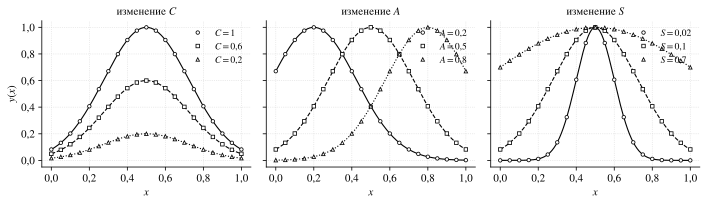

In [25]:
x = np.linspace(0.0, 1.0, 21)            # узлы x_j = 0,05 j
assert x.size == 21 and x[0] == 0.0 and x[-1] == 1.0
assert np.allclose(np.diff(x), 0.05)

def pulse(x, C, A, S):
    # Формула (3.33). Деление на S, а не на S^2.
    return C * np.exp(-(x - A) ** 2 / S)

xd = np.linspace(0, 1, 401)               # плотная сетка — только для рисунков
fig, ax = plt.subplots(1, 3, figsize=(10, 3.0), sharey=True)
styles = ["-", "--", ":"]
marks = ["o", "s", "^"]
cases = [("C", [1.0, 0.6, 0.2], dict(A=0.5, S=0.1)),
         ("A", [0.2, 0.5, 0.8], dict(C=1.0, S=0.1)),
         ("S", [0.02, 0.1, 0.7], dict(C=1.0, A=0.5))]
for k, (name, vals, fixed) in enumerate(cases):
    for v, ls, mk in zip(vals, styles, marks):
        par = dict(fixed); par[name] = v
        ax[k].plot(xd, pulse(xd, **par), color="black", ls=ls, lw=1.1)
        ax[k].plot(x, pulse(x, **par), mk, ms=3.5, mfc="white", mec="black", mew=0.8,
                   label=f"${name}={v:g}$".replace(".", "{,}"))
    ax[k].set_xlabel("$x$"); ax[k].legend(loc="upper right")
    ax[k].set_title(f"изменение ${name}$")
ax[0].set_ylabel("$y(x)$")
fig.tight_layout(); savefig(fig, "step1_pulses"); plt.show()

*Рис. Ш1.* Влияние амплитуды, положения и ширины на форму импульса (аналог рис. 3.8). Линии — непрерывная функция, маркеры — 21 отсчёт, которые поступают на вход сети.

**Наблюдение.** При $S=0{,}02$ импульс занимает лишь несколько узлов, а при $S=0{,}7$ на отрезке видна только пологая часть колокола. В обоих крайних случаях информативность отсчётов падает по разным причинам; это пригодится при анализе максимальных ошибок на шаге 4. В учебной выборке $S\in[0{,}1;\,1]$, поэтому узкие импульсы в неё не попадают — это граница применимости модели.

> **Перекрёстная связь.** Выбор 21 узла нельзя обосновать теоремой Котельникова: гауссов импульс не имеет строго ограниченного спектра (см. исторический контекст главы 3). Достаточность сетки оценивается по точности и устойчивости восстановления параметров — инженерным, а не спектральным критерием. К спектральному описанию сигналов пособие вернётся в главах 7 и 14.

## Шаг 2. Фиксированные базисы: Тейлор, МНК, гармоники, ReLU

Этот шаг соответствует скрипту `basis_engee.jl`. Все модели здесь имеют вид линейной комбинации базисных функций

$$
\hat f(x)=\sum_{k=0}^{r}c_k\,\psi_k(x), \tag{3.5}
$$

где $\psi_k$ — заранее выбранные функции (признаки), $c_k$ — коэффициенты, $r$ — порядок модели. В терминах нейросети это слой **фиксированных** признаков и один линейный выходной узел с обучаемыми весами $c_k$.

### 2а. Полином Тейлора и полином МНК для $e^x$

Строим матрицу $\mathbf V$ размера $41\times4$ с элементами $V_{ik}=x_i^{k}$ ($x_i$ — 41 равномерный узел на $[-1,1]$) и решаем задачу МНК (3.6) через QR/SVD (`lstsq`), не формируя $\mathbf V^{\mathsf T}\mathbf V$. Коэффициенты Тейлора в точке $x_0=0$ равны $f^{(k)}(0)/k!=1/k!$.

,c0,c1,c2,c3,Max |ошибка|,RMSE
"Тейлор, x0 = 0",1.00000,1.00000,0.50000,0.16667,0.05162,0.01452
"МНК, 41 узел",0.99593,0.99776,0.53853,0.17659,0.00948,0.00339


Оценка остатка (3.22): e/24 = 0.11326;  фактическая max ошибка Тейлора = 0.05162
cond(V) = 7.82,  cond(V^T V) = 61.19  (квадрат)


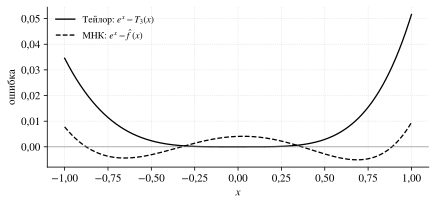

In [26]:
xb = np.linspace(-1, 1, 41)
V = np.vander(xb, 4, increasing=True)                 # столбцы 1, x, x^2, x^3
c_lsq, *_ = np.linalg.lstsq(V, np.exp(xb), rcond=None)
c_tay = np.array([1.0, 1.0, 0.5, 1/6])

xdense = np.linspace(-1, 1, 4001)                      # отдельная плотная сетка для ошибок
Vd = np.vander(xdense, 4, increasing=True)
err_tay = np.exp(xdense) - Vd @ c_tay
err_lsq = np.exp(xdense) - Vd @ c_lsq

tab = pd.DataFrame({
    "c0": [c_tay[0], c_lsq[0]], "c1": [c_tay[1], c_lsq[1]],
    "c2": [c_tay[2], c_lsq[2]], "c3": [c_tay[3], c_lsq[3]],
    "Max |ошибка|": [np.abs(err_tay).max(), np.abs(err_lsq).max()],
    "RMSE": [np.sqrt(np.mean(err_tay**2)), np.sqrt(np.mean(err_lsq**2))]},
    index=["Тейлор, x0 = 0", "МНК, 41 узел"])
display(tab.round(5))
print(f"Оценка остатка (3.22): e/24 = {np.e/24:.5f};  фактическая max ошибка Тейлора = {np.e - 8/3:.5f}")
print(f"cond(V) = {np.linalg.cond(V):.2f},  cond(V^T V) = {np.linalg.cond(V.T @ V):.2f}  (квадрат)")

fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.plot(xdense, err_tay, "k-", label="Тейлор: $e^x-T_3(x)$")
ax.plot(xdense, err_lsq, "k--", label="МНК: $e^x-\\hat f(x)$")
ax.axhline(0, color="0.5", lw=0.6)
ax.set_xlabel("$x$"); ax.set_ylabel("ошибка"); ax.legend()
fig.tight_layout(); savefig(fig, "step2a_taylor_vs_lsq"); plt.show()

*Рис. Ш2а.* Ошибка полинома Тейлора и полинома МНК третьей степени для $e^x$.

**Вывод.** Обе модели принадлежат одному семейству кубических полиномов и реализуются одной и той же сетью с признаками $1,x,x^2,x^3$. Различается **критерий** определения весов: Тейлор согласует производные в одной точке (ошибка растёт к краю $x=1$ и достигает $e-8/3\approx0{,}0516$, как в примере 3.2), МНК распределяет ошибку по всему отрезку и даёт меньший максимум. Число обусловленности $\mathbf V^{\mathsf T}\mathbf V$ равно квадрату числа обусловленности $\mathbf V$ — это численное обоснование отказа от нормальных уравнений.

### 2б. Гармонический сигнал: восстановление коэффициентов (пример 3.4)

Функция $f(x)=0{,}7+1{,}2\cos x-0{,}4\sin 2x$ точно принадлежит пространству гармоник до второго порядка. Признаки: $[1,\cos x,\sin x,\cos 2x,\sin 2x]$; узлы — 41 различная точка одного периода $[-\pi,\pi)$.

In [27]:
xh = np.linspace(-np.pi, np.pi, 41, endpoint=False)
F = np.column_stack([np.ones_like(xh), np.cos(xh), np.sin(xh), np.cos(2*xh), np.sin(2*xh)])
yh = 0.7 + 1.2*np.cos(xh) - 0.4*np.sin(2*xh)
c_h, *_ = np.linalg.lstsq(F, yh, rcond=None)
c_true = np.array([0.7, 1.2, 0.0, 0.0, -0.4])
display(pd.DataFrame({"эталон": c_true, "МНК": c_h, "|разность|": np.abs(c_h - c_true)},
                     index=["1", "cos x", "sin x", "cos 2x", "sin 2x"]))

# Наложение спектров: на сетке из N узлов гармоники k и k+N неразличимы
N = 8; xs = np.linspace(-np.pi, np.pi, N, endpoint=False)
print("Гармоники sin(1x) и sin(9x) на 8 узлах совпадают:",
      np.allclose(np.sin(xs), np.sin(9*xs)))

,эталон,МНК,|разность|
1,0.7,7.000000e-01,0.000000e+00
cos x,1.2,1.200000e+00,2.220446e-16
sin x,0.0,3.402039e-17,3.402039e-17
cos 2x,0.0,-9.693009e-18,9.693009e-18
sin 2x,-0.4,-4.000000e-01,5.551115e-17


Гармоники sin(1x) и sin(9x) на 8 узлах совпадают: True


Расхождение имеет порядок машинного округления: данные без шума, модель содержит все нужные гармоники. Последняя строка иллюстрирует оговорку п. 3.2.4: **числа узлов недостаточно**, если разные гармоники неразличимы на выбранной сетке (наложение спектров).

### 2в. Ступенчатая функция и эффект Гиббса

Частичные суммы $\dfrac4\pi\sum_{k\le K,\ k\ \text{нечётное}}\dfrac{\sin kx}{k}$ приближают периодическую ступеньку $\operatorname{sign}(\sin x)$, $K$ — наибольший номер гармоники. Измерим высоту выброса у скачка.

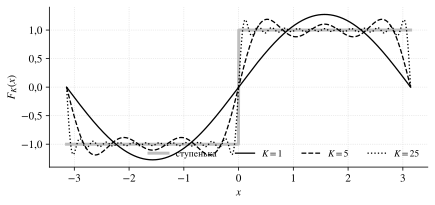

,K,max частичной суммы
0,5,1.18836
1,25,1.17947
2,101,1.17901
3,401,1.17898


In [28]:
xg = np.linspace(1e-5, np.pi - 1e-5, 200001)
def square_partial(xv, K):
    return 4/np.pi * sum(np.sin(k*xv)/k for k in range(1, K+1, 2))

fig, ax = plt.subplots(figsize=(6.2, 3.0))
xp = np.linspace(-np.pi, np.pi, 2001)
ax.plot(xp, np.sign(np.sin(xp)), color="0.75", lw=3, label="ступенька")
rows = []
for K, ls in zip([1, 5, 25], ["-", "--", ":"]):
    ax.plot(xp, square_partial(xp, K), "k", ls=ls, label=f"$K={K}$")
for K in [5, 25, 101, 401]:
    rows.append({"K": K, "max частичной суммы": square_partial(xg, K).max()})
ax.set_xlabel("$x$"); ax.set_ylabel("$F_K(x)$"); ax.legend(ncol=4, loc="lower right")
fig.tight_layout(); savefig(fig, "step2c_gibbs"); plt.show()
display(pd.DataFrame(rows).round(5))

*Рис. Ш2в.* Частичные суммы ряда Фурье для ступенчатой функции (аналог рис. 3.7).

Максимум частичной суммы стремится к $\approx1{,}179$, а не к $1$: область колебаний сужается, но относительная высота выброса около $9\%$ от скачка не исчезает. Для конечной гармонической сети это означает **систематическую** ошибку у разрывов, которую нельзя устранить увеличением числа узлов.

### 2г. Кусочно-линейная интерполяция как сеть ReLU (формула 3.32, задача 6)

Линейный сплайн с узлами $t_0<\dots<t_K$ и наклонами $s_k$ представляется как
$$
p(x)=p(t_0)+s_0(x-t_0)+\sum_{k=1}^{K-1}(s_k-s_{k-1})\,\mathrm{ReLU}(x-t_k),\qquad \mathrm{ReLU}(u)=\max(0,u). \tag{3.32}
$$
Построим такую сеть для $x^2$ на узлах $-1,-0{,}5,0,0{,}5,1$; ожидаемая максимальная ошибка $h^2/4=1/16$, где $h=0{,}5$ — шаг узлов.

In [29]:
relu = lambda u: np.maximum(0.0, u)
t = np.array([-1.0, -0.5, 0.0, 0.5, 1.0]); f = t**2
s = np.diff(f) / np.diff(t)                         # наклоны на интервалах
def relu_spline(xv):
    out = f[0] + s[0]*(xv - t[0])
    for k in range(1, len(t)-1):
        out = out + (s[k] - s[k-1]) * relu(xv - t[k])   # веса выходного узла = скачки наклона
    return out
xr = np.linspace(-1, 1, 20001)
print("Веса ReLU-элементов:", np.diff(s), "| смещения:", -t[1:-1])
print("max |x^2 - p(x)| =", np.abs(xr**2 - relu_spline(xr)).max(), " (теория: 1/16 = 0.0625)")

Веса ReLU-элементов: [1. 1. 1.] | смещения: [ 0.5 -0.  -0.5]
max |x^2 - p(x)| = 0.0625  (теория: 1/16 = 0.0625)


> **Перекрёстная связь.** На шаге 2 веса **выводятся** из формулы, как пороги логических нейронов в главе 2 (п. 2.3.8: «синтез сети»). На шаге 4 веса будут **обучаться** по данным. Одинаковая архитектура не означает одинакового способа определения параметров — это сквозная мысль глав 2 и 3. Сеть ReLU из п. 2г — прямой мост к главе 4: сплайн по каждой переменной — это и есть «обучаемая одномерная функция на ребре» сети Колмогорова–Арнольда.

## Шаг 3. Общие данные практикума и аналитическое восстановление

### 3а. Данные

Параметры $C,A,S$ каждого примера выбираются независимо из равномерного распределения на $[0{,}1;\,1]$; по ним вычисляются 21 отсчёт. Разбиение: 3000 обучающих, 600 валидационных, 600 тестовых сигналов.

Если в каталоге `data/` уже лежат общие файлы `samples.csv` и `initial_weights.csv` из цифрового комплекта, тетрадь использует их — тогда результаты сопоставимы с Engee и MATLAB. Иначе файлы генерируются генератором NumPy с начальным значением $20260929$ и сохраняются в том же формате. Формат `samples.csv`: одна строка — один пример; столбцы: часть выборки ($1$ — обучение, $2$ — валидация, $3$ — тест), затем $C,A,S$, затем 21 отсчёт. При чтении массивы транспонируются к соглашению «пример по столбцу».

**Важно.** Если файлы сгенерированы здесь, а не взяты из комплекта, численные результаты будут близки к контрольным значениям табл. 3.2, но не обязаны совпадать с ними до последнего знака.

In [30]:
SEED = 20260929
SIZES = (21, 21, 15, 3)
N_TR, N_VA, N_TE = 3000, 600, 600
f_samples, f_weights = DATA / "samples.csv", DATA / "initial_weights.csv"

def xavier(sizes, rng):
    # W^(l): (n_l x n_{l-1}), равномерно в ±sqrt(6/(n_in+n_out)); b^(l) = 0.
    w = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        lim = np.sqrt(6.0 / (n_in + n_out))
        w += [rng.uniform(-lim, lim, size=(n_out, n_in)), np.zeros((n_out, 1))]
    return w

def flatten(w):   return np.concatenate([a.ravel() for a in w])
def unflatten(v, sizes):
    w, pos = [], 0
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        w.append(v[pos:pos + n_out*n_in].reshape(n_out, n_in)); pos += n_out*n_in
        w.append(v[pos:pos + n_out].reshape(n_out, 1));         pos += n_out
    return w

if f_samples.exists() and f_weights.exists():
    source = "файлы цифрового комплекта (data/)"
else:
    rng = np.random.default_rng(SEED)
    M = N_TR + N_VA + N_TE
    par = rng.uniform(0.1, 1.0, size=(M, 3))
    sig = pulse(x[None, :], par[:, [0]], par[:, [1]], par[:, [2]])
    part = np.r_[np.full(N_TR, 1), np.full(N_VA, 2), np.full(N_TE, 3)]
    np.savetxt(f_samples, np.column_stack([part, par, sig]), delimiter=",", fmt="%.17g")
    np.savetxt(f_weights, flatten(xavier(SIZES, rng)), delimiter=",", fmt="%.17g")
    source = f"сгенерированы NumPy, seed = {SEED}"

raw = np.loadtxt(f_samples, delimiter=",")
part, T_all, P_all = raw[:, 0].astype(int), raw[:, 1:4].T, raw[:, 4:].T   # пример по столбцу
w0 = unflatten(np.loadtxt(f_weights, delimiter=","), SIZES)

P_tr, T_tr = P_all[:, part == 1], T_all[:, part == 1]
P_va, T_va = P_all[:, part == 2], T_all[:, part == 2]
P_te, T_te = P_all[:, part == 3], T_all[:, part == 3]
print("Источник данных:", source)
print("P_tr", P_tr.shape, "T_tr", T_tr.shape, "| P_va", P_va.shape, "| P_te", P_te.shape)
assert P_tr.shape == (21, 3000) and P_va.shape == (21, 600) and P_te.shape == (21, 600)
assert T_all.min() >= 0.1 and T_all.max() <= 1.0

Источник данных: файлы цифрового комплекта (data/)
P_tr (21, 3000) T_tr (3, 3000) | P_va (21, 600) | P_te (21, 600)


### 3б. Аналитическое восстановление (формулы 3.34–3.35)

При отсутствии шума и положительных отсчётах логарифм импульса — квадратичный полином:
$$
\ln y(x)=q_0+q_1x+q_2x^2,\qquad q_2=-\frac1S,\quad q_1=\frac{2A}{S},\quad q_0=\ln C-\frac{A^2}{S}. \tag{3.34}
$$
Коэффициенты $q_0,q_1,q_2$ находятся линейным МНК, после чего при $q_2<0$
$$
S=-\frac1{q_2},\qquad A=-\frac{q_1}{2q_2},\qquad C=\exp\!\left(q_0-\frac{q_1^2}{4q_2}\right). \tag{3.35}
$$
Функция ниже возвращает также маску **применимости**: метод неприменим, если среди отсчётов есть неположительные или если $q_2\ge0$. Такие случаи нельзя незаметно исключать при сравнении — их число нужно сообщать.

In [31]:
Vq = np.column_stack([np.ones(21), x, x**2])

def log_recover(P):
    # Аналитическое восстановление (3.34)-(3.35). P: 21 x M. Возвращает (3 x M, маска применимости).
    M = P.shape[1]
    est = np.full((3, M), np.nan)
    ok = np.all(P > 0, axis=0)
    if ok.any():
        q, *_ = np.linalg.lstsq(Vq, np.log(P[:, ok]), rcond=None)
        q0, q1, q2 = q
        good = q2 < 0
        idx = np.flatnonzero(ok)[good]
        q0, q1, q2 = q0[good], q1[good], q2[good]
        est[:, idx] = np.vstack([np.exp(q0 - q1**2/(4*q2)), -q1/(2*q2), -1/q2])
        ok[np.flatnonzero(ok)[~good]] = False
    return est, ok

def metrics(T, That, names=("C", "A", "S")):
    e = That - T
    return pd.DataFrame({"RMSE": np.sqrt(np.nanmean(e**2, axis=1)),
                         "MAE": np.nanmean(np.abs(e), axis=1),
                         "Max |ошибка|": np.nanmax(np.abs(e), axis=1)}, index=list(names))

est_log, ok_log = log_recover(P_te)
print(f"Метод применим к {ok_log.sum()} из {ok_log.size} чистых тестовых сигналов")
display(metrics(T_te, est_log).map(lambda v: f"{v:.2e}"))

# Листинг 3.2: пример из исходной лабораторной работы
p_ex = pulse(x, 0.2, 0.8, 0.7)
print("Восстановление (0.2, 0.8, 0.7):", log_recover(p_ex[:, None])[0].ravel())

Метод применим к 600 из 600 чистых тестовых сигналов


,RMSE,MAE,Max |ошибка|
C,5.41e-16,3.04e-16,3.77e-15
A,2.79e-16,2.08e-16,1.28e-15
S,4.17e-16,2.34e-16,2.89e-15


Восстановление (0.2, 0.8, 0.7): [0.2 0.8 0.7]


Ошибки порядка $10^{-14}$–$10^{-15}$: аналитический метод использует **точную структуру** сигнала. Это эталон сравнения, а не конкурент сети на чистых данных. Нейросеть станет полезной там, где структура известна неточно, где нужен быстрый ответ без итераций или где логарифмирование разрушается шумом (шаг 7).

## Шаг 4. Сеть 21–21–15–3: обучение и отбор по валидации

### 4а. Нормировка

Входы нормируются по каждому каналу $j$ средним $\mu_j$ и стандартным отклонением $s_j$, вычисленными **только по обучающей части**; цели переводятся из известного диапазона $[0{,}1;\,1]$ в $[-1;1]$:
$$
\tilde p_j=\frac{p_j-\mu_j}{s_j},\qquad \tilde t_q=2\,\frac{t_q-0{,}1}{0{,}9}-1,\qquad t_q=0{,}1+0{,}45(\tilde t_q+1). \tag{3.37}
$$
Нулевое или слишком малое $s_j$ ограничивается снизу. Параметры нормировки фиксируются и затем применяются к валидационным, тестовым и новым сигналам без пересчёта (п. 3.1.3).

In [32]:
class Normalizer:
    def __init__(self, P_train, floor=1e-8):
        self.mu = P_train.mean(axis=1, keepdims=True)
        self.s = np.maximum(P_train.std(axis=1, keepdims=True), floor)
    def x(self, P):   return (P - self.mu) / self.s
    @staticmethod
    def t(T):         return 2.0 * (T - 0.1) / 0.9 - 1.0
    @staticmethod
    def t_inv(Tn):    return 0.1 + 0.45 * (Tn + 1.0)

norm = Normalizer(P_tr)
print("mu_j (первые 5):", norm.mu.ravel()[:5])
print("s_j  (первые 5):", norm.s.ravel()[:5])

mu_j (первые 5): [0.29762 0.32195 0.34578 0.36864 0.39006]
s_j  (первые 5): [0.23102 0.23866 0.24458 0.24858 0.2506 ]


### 4б. Прямой проход, критерий и градиенты

Для пакета из $B$ сигналов (по столбцам матрицы $\mathbf X$) скрытые слои вычисляют $\mathbf h^{(1)}=\varphi(\mathbf W^{(1)}\mathbf X+\mathbf b^{(1)})$, $\mathbf h^{(2)}=\varphi(\mathbf W^{(2)}\mathbf h^{(1)}+\mathbf b^{(2)})$, выходной слой линеен: $\hat{\mathbf t}=\mathbf W^{(3)}\mathbf h^{(2)}+\mathbf b^{(3)}$. Критерий обучения — MSE по трём нормированным выходам и всем примерам пакета:
$$
L=\frac1{3B}\sum_{i=1}^{B}\sum_{q=1}^{3}\bigl(\hat{\tilde t}{}_q^{(i)}-\tilde t_q^{(i)}\bigr)^2. \tag{3.38}
$$
Градиенты выписаны явно, как в листинге 3.4: ошибка выходного слоя передаётся назад через транспонированную матрицу весов и умножается на производную сигмоиды $\varphi'(u)=h(1-h)$. Перед обучением выполним **проверку градиентов** конечными разностями — обязательная инженерная практика для ручной реализации.

In [33]:
sigm = lambda u: 1.0 / (1.0 + np.exp(-u))

def forward(w, X):                                     # листинг 3.3
    h1 = sigm(w[0] @ X + w[1])
    h2 = sigm(w[2] @ h1 + w[3])
    return w[4] @ h2 + w[5], h1, h2

def loss(w, X, T):
    return np.mean((forward(w, X)[0] - T) ** 2)

def grads(w, X, T):                                    # листинг 3.4
    y, h1, h2 = forward(w, X)
    d3 = 2.0 * (y - T) / T.size
    d2 = (w[4].T @ d3) * h2 * (1 - h2)
    d1 = (w[2].T @ d2) * h1 * (1 - h1)
    return [d1 @ X.T, d1.sum(1, keepdims=True), d2 @ h1.T,
            d2.sum(1, keepdims=True), d3 @ h2.T, d3.sum(1, keepdims=True)]

def n_params(sizes):
    return sum(n_out*n_in + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))

# Проверка градиентов на 8 случайных элементах
Xc, Tc = norm.x(P_tr[:, :16]), norm.t(T_tr[:, :16])
g = grads(w0, Xc, Tc); rng_c = np.random.default_rng(1); worst = 0.0
for _ in range(8):
    l = rng_c.integers(6); idx = tuple(rng_c.integers(s) for s in w0[l].shape)
    wp = copy.deepcopy(w0); wm = copy.deepcopy(w0); h = 1e-6
    wp[l][idx] += h; wm[l][idx] -= h
    num = (loss(wp, Xc, Tc) - loss(wm, Xc, Tc)) / (2*h)
    worst = max(worst, abs(num - g[l][idx]) / max(1e-12, abs(num) + abs(g[l][idx])))
print(f"Число параметров сети {SIZES}: {n_params(SIZES)}")
print(f"Наибольшая относительная ошибка градиента: {worst:.2e}")
assert n_params(SIZES) == 840 and worst < 1e-5

Число параметров сети (21, 21, 15, 3): 840
Наибольшая относительная ошибка градиента: 1.04e-08


### 4в. Метод Adam и отбор состояния по валидации

Параметры обновляются методом Adam: шаг $\eta=0{,}003$, $\beta_1=0{,}9$, $\beta_2=0{,}999$, $\kappa=10^{-8}$, размер пакета $B=128$, 400 эпох. Обучающие примеры обрабатываются в одном и том же порядке; последний неполный пакет участвует в обучении. После каждой эпохи вычисляется валидационная ошибка и сохраняется копия параметров с её минимумом; в конце используется эта копия. **Тестовая часть в выборе не участвует.**

In [34]:
def train(w_init, Xtr, Ttr, Xva, Tva, eta=0.003, b1=0.9, b2=0.999, kappa=1e-8,
          batch=128, epochs=400):
    w = [a.copy() for a in w_init]
    m = [np.zeros_like(a) for a in w]; v = [np.zeros_like(a) for a in w]
    k, N = 0, Xtr.shape[1]
    hist_tr, hist_va = [], []
    best = (np.inf, 0, None)
    for ep in range(1, epochs + 1):
        for s0 in range(0, N, batch):
            g = grads(w, Xtr[:, s0:s0+batch], Ttr[:, s0:s0+batch])   # все градиенты — до обновления
            k += 1
            for i in range(6):
                m[i] = b1*m[i] + (1-b1)*g[i]
                v[i] = b2*v[i] + (1-b2)*g[i]**2
                w[i] -= eta * (m[i]/(1-b1**k)) / (np.sqrt(v[i]/(1-b2**k)) + kappa)
        hist_tr.append(loss(w, Xtr, Ttr)); hist_va.append(loss(w, Xva, Tva))
        if hist_va[-1] < best[0]:
            best = (hist_va[-1], ep, [a.copy() for a in w])
    return dict(w=best[2], best_va=best[0], best_ep=best[1],
                hist_tr=np.array(hist_tr), hist_va=np.array(hist_va))

def predict(model, P):
    return Normalizer.t_inv(forward(model["w"], model["norm"].x(P))[0])

t0 = time.perf_counter()
base = train(w0, norm.x(P_tr), norm.t(T_tr), norm.x(P_va), norm.t(T_va))
base["norm"] = norm
print(f"Время обучения: {time.perf_counter()-t0:.1f} с")
print(f"Минимальная валидационная MSE = {base['best_va']:.5e} на эпохе {base['best_ep']}")
print("Контрольный запуск главы 3: 1,06649e-03 на эпохе 400")

Время обучения: 4.4 с
Минимальная валидационная MSE = 6.81724e-04 на эпохе 400
Контрольный запуск главы 3: 1,06649e-03 на эпохе 400


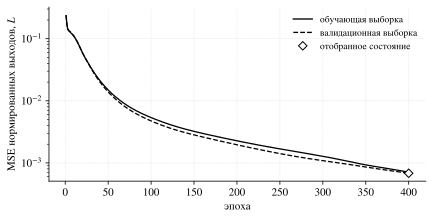

In [35]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ep = np.arange(1, len(base["hist_tr"]) + 1)
ax.semilogy(ep, base["hist_tr"], "k-", label="обучающая выборка")
ax.semilogy(ep, base["hist_va"], "k--", label="валидационная выборка")
ax.plot(base["best_ep"], base["best_va"], "D", mfc="white", mec="black", ms=6,
        label="отобранное состояние")
ax.set_xlabel("эпоха"); ax.set_ylabel("MSE нормированных выходов, $L$")
ax.legend(); fig.tight_layout(); savefig(fig, "step4_learning_curve"); plt.show()

*Рис. Ш4а.* Изменение ошибки при обучении сети (аналог рис. 3.10). Совместное убывание обеих кривых согласуется с улучшением качества на независимых данных, но **не доказывает** достижения глобального минимума.

### 4г. Качество на тестовой выборке в исходной шкале

In [36]:
T_hat = predict(base, P_te)
tab_nn = metrics(T_te, T_hat)
display(tab_nn.map(lambda v: comma(v)))
display(Markdown("Контрольные значения табл. 3.2 (RMSE): $C$ — 0,00956; $A$ — 0,01235; $S$ — 0,02306."))

out = (T_hat < 0.1) | (T_hat > 1.0)
nonphys = (T_hat[0] <= 0) | (T_hat[2] <= 0)
print("Прогнозы вне диапазона [0,1; 1] по C, A, S:", out.sum(axis=1), "из", T_hat.shape[1])
print("Физически недопустимые прогнозы (C<=0 или S<=0):", nonphys.sum())

,RMSE,MAE,Max |ошибка|
C,"0,00929","0,00675","0,06213"
A,"0,01241","0,00822","0,08635"
S,"0,01791","0,01092","0,15317"


Контрольные значения табл. 3.2 (RMSE): $C$ — 0,00956; $A$ — 0,01235; $S$ — 0,02306.

Прогнозы вне диапазона [0,1; 1] по C, A, S: [ 8  5 14] из 600
Физически недопустимые прогнозы (C<=0 или S<=0): 0


Выход за диапазон обучения учитывается как **диагностический** результат и не скрывается обрезанием значений: линейный выходной слой сам по себе не гарантирует принадлежности прогноза диапазону (п. 3.4.3).

### 4д. Графики «эталон — прогноз»

Показаны 150 из 600 тестовых сигналов; подвыборка случайная, но в неё обязательно включены случаи максимальной ошибки по каждому параметру (ромбы). Прямая равенства обязательна: высокая корреляция не исключает систематического смещения или масштабной ошибки.

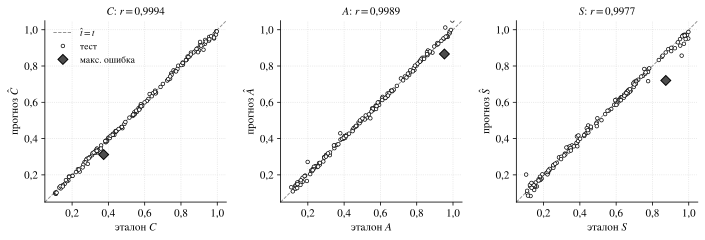

In [37]:
def ref_pred_plots(T, That, fname, title_suffix=""):
    rng_s = np.random.default_rng(7)
    worst_idx = np.abs(That - T).argmax(axis=1)
    pool = np.setdiff1d(np.arange(T.shape[1]), worst_idx)
    sub = np.r_[worst_idx, rng_s.choice(pool, 150 - len(set(worst_idx)), replace=False)]
    sub = np.unique(sub)
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
    for q, name in enumerate(["C", "A", "S"]):
        a = ax[q]
        a.plot([0.05, 1.05], [0.05, 1.05], color="0.55", ls="--", lw=0.9, label="$\\hat t=t$")
        a.plot(T[q, sub], That[q, sub], "o", ms=3.6, mfc="white", mec="black", mew=0.7,
               label="тест")
        a.plot(T[q, worst_idx[q]], That[q, worst_idx[q]], "D", ms=7, mfc="0.3", mec="black",
               label="макс. ошибка")
        r = np.corrcoef(T[q], That[q])[0, 1]
        a.set_title(f"${name}$: $r={r:.4f}$".replace(".", "{,}") + title_suffix)
        a.set_xlabel(f"эталон ${name}$"); a.set_ylabel(f"прогноз $\\hat {name}$")
        a.set_xlim(0.05, 1.05); a.set_ylim(0.05, 1.05); a.set_aspect("equal")
    ax[0].legend(loc="upper left")
    fig.tight_layout(); savefig(fig, fname); plt.show()
    return worst_idx

worst_idx = ref_pred_plots(T_te, T_hat, "step4_ref_vs_pred")

*Рис. Ш4б.* Эталонные значения $C$, $A$, $S$ и прогнозы сети (аналог рис. 3.11–3.13); $r$ — выборочный коэффициент корреляции по всем 600 сигналам.

Особого внимания требует параметр $S$: его максимальная ошибка заметно больше средней. Посмотрим, какие сигналы дают наибольшие ошибки, и сопоставим их с формой импульса.

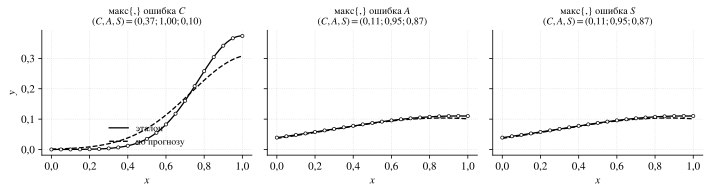

MAE(S)          Max(S)        
параметр         A       S       A       S
интервал                                  
[0.1; 0.4]  0.0125  0.0118  0.1037  0.0977
[0.4; 0.7]  0.0092  0.0087  0.0584  0.0344
[0.7; 1.0]  0.0113  0.0126  0.1532  0.1532

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(10, 2.9), sharey=True)
for q, name in enumerate(["C", "A", "S"]):
    i = worst_idx[q]; C, A, S = T_te[:, i]; Ch, Ah, Sh = T_hat[:, i]
    ax[q].plot(xd, pulse(xd, C, A, S), "k-", label="эталон")
    if Ch > 0 and Sh > 0:
        ax[q].plot(xd, pulse(xd, Ch, Ah, Sh), "k--", label="по прогнозу")
    ax[q].plot(x, P_te[:, i], "o", ms=3.2, mfc="white", mec="black", mew=0.7)
    ax[q].set_title(f"макс. ошибка ${name}$\n$(C,A,S)=({C:.2f};{A:.2f};{S:.2f})$".replace(".", "{,}"),
                    fontsize=10)
    ax[q].set_xlabel("$x$")
ax[0].set_ylabel("$y$"); ax[0].legend(loc="lower center")
fig.tight_layout(); savefig(fig, "step4_worst_cases"); plt.show()

# Ошибка S в зависимости от S и от A: где сеть ошибается сильнее
eS = np.abs(T_hat[2] - T_te[2])
bins = np.linspace(0.1, 1.0, 4)
rows = []
for lo, hi in zip(bins[:-1], bins[1:]):
    for nm, q in [("S", 2), ("A", 1)]:
        msk = (T_te[q] >= lo) & (T_te[q] < hi + 1e-12)
        rows.append({"параметр": nm, "интервал": f"[{lo:.1f}; {hi:.1f}]",
                     "MAE(S)": eS[msk].mean(), "Max(S)": eS[msk].max(), "n": msk.sum()})
display(pd.DataFrame(rows).pivot(index="интервал", columns="параметр",
                                 values=["MAE(S)", "Max(S)"]).round(4))

*Рис. Ш4в.* Сигналы, на которых достигаются максимальные ошибки по каждому параметру.

**Инженерная интерпретация.** Наибольшие ошибки $S$ обычно возникают у **широких** импульсов и у импульсов с максимумом **у края** отрезка: на интервале $[0,1]$ видна лишь пологая часть колокола, и изменения $C$ и $S$ слабо меняют данные. Единственность решения без шума ещё не означает его устойчивости (п. 3.4.2). Перед практическим применением нужно задать допуск и оценить долю прогнозов вне допуска; средняя ошибка этого не заменяет.

> **Перекрёстная связь.** Слабая чувствительность данных к параметрам — признак плохой обусловленности обратной задачи. Ровно этот механизм в общем виде (некорректные задачи по Адамару, регуляризация Тихонова) рассматривается в главе 6; градиентный метод и Adam — в главе 5.

## Шаг 5. Контрольный пример $(C,A,S)=(0{,}2;\,0{,}8;\,0{,}7)$

Восстановим параметры сигнала из исходной лабораторной работы и сравним исходный импульс с импульсом, построенным по прогнозу. Сравнение сигналов выполняется только при физически допустимом прогнозе $C>0$, $S>0$.

Прогноз сети:           [0.19062 0.81573 0.71764]   (контрольный запуск: 0.20750, 0.81689, 0.71155)
Аналитическое решение:  [0.2 0.8 0.7]


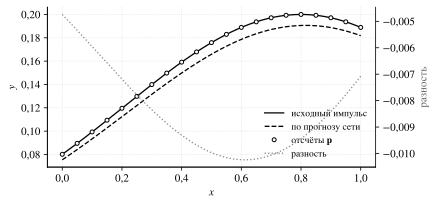

In [39]:
t_ex = predict(base, p_ex[:, None]).ravel()
print("Прогноз сети:          ", t_ex, "  (контрольный запуск: 0.20750, 0.81689, 0.71155)")
print("Аналитическое решение: ", log_recover(p_ex[:, None])[0].ravel())
assert t_ex[0] > 0 and t_ex[2] > 0

fig, ax = plt.subplots(figsize=(6.2, 3.0))
ax.plot(xd, pulse(xd, 0.2, 0.8, 0.7), "k-", label="исходный импульс")
ax.plot(xd, pulse(xd, *t_ex), "k--", label="по прогнозу сети")
ax.plot(x, p_ex, "o", ms=4, mfc="white", mec="black", label="отсчёты $\\mathbf{p}$")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(xd, pulse(xd, *t_ex) - pulse(xd, 0.2, 0.8, 0.7), color="0.55", ls=":", label="разность")
ax2.set_ylabel("разность", color="0.4"); ax2.spines["right"].set_visible(True)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc="lower right")
fig.tight_layout(); savefig(fig, "step5_example"); plt.show()

*Рис. Ш5.* Исходный импульс и импульс, восстановленный по прогнозу сети (правая ось — разность). Результат относится именно к описанному расчёту и не является универсальным ответом, обязательным после любого обучения.

## Шаг 6. Объём обучающей выборки и размер скрытых слоёв

Повторяем обучение на первых 100, 500 и 3000 обучающих сигналах при **одних и тех же** валидационной и тестовой выборках. Для каждого объёма сравниваем по **валидации** две архитектуры — 21–21–15–3 (840 параметров) и 21–32–16–3 (1283 параметра, задача 8) — и только для выбранной заранее по валидации архитектуры вычисляем тестовую ошибку. Нормировка входов пересчитывается по той обучающей части, которая реально используется.

Число обновлений за 400 эпох зависит от объёма: при 100 примерах и $B=128$ за эпоху выполняется одно обновление. Поэтому часть различий объясняется не только объёмом данных, но и числом шагов оптимизации — это нужно оговорить в отчёте.

In [40]:
rows, chosen = [], {}
for N in [100, 500, 3000]:
    nrm = Normalizer(P_tr[:, :N])
    cand = []
    for sizes in [(21, 21, 15, 3), (21, 32, 16, 3)]:
        w_init = w0 if sizes == SIZES else xavier(sizes, np.random.default_rng(SEED + 1))
        mdl = train(w_init, nrm.x(P_tr[:, :N]), nrm.t(T_tr[:, :N]),
                    nrm.x(P_va), nrm.t(T_va))
        mdl["norm"] = nrm
        cand.append((mdl["best_va"], sizes, mdl))
        rows.append({"N обуч.": N, "архитектура": "–".join(map(str, sizes)),
                     "параметров": n_params(sizes), "обновлений": 400*int(np.ceil(N/128)),
                     "валид. MSE": mdl["best_va"], "эпоха": mdl["best_ep"]})
    best_va, sizes, mdl = min(cand, key=lambda c: c[0])
    rmse = np.sqrt(np.mean((predict(mdl, P_te) - T_te)**2, axis=1))
    chosen[N] = dict(arch="–".join(map(str, sizes)), RMSE_C=rmse[0], RMSE_A=rmse[1], RMSE_S=rmse[2])

display(pd.DataFrame(rows).style.format({"валид. MSE": "{:.3e}"}))
display(Markdown("**Тест только для архитектуры, выбранной по валидации:**"))
display(pd.DataFrame(chosen).T.rename_axis("N обуч.").style.format(
    {"RMSE_C": "{:.5f}", "RMSE_A": "{:.5f}", "RMSE_S": "{:.5f}"}))

,N обуч.,архитектура,параметров,обновлений,валид. MSE,эпоха
0,100,21–21–15–3,840,400,9.369e-02,400
1,100,21–32–16–3,1283,400,8.709e-02,400
2,500,21–21–15–3,840,1600,8.699e-03,400
3,500,21–32–16–3,1283,1600,9.463e-03,400
4,3000,21–21–15–3,840,9600,6.817e-04,400
5,3000,21–32–16–3,1283,9600,7.176e-04,400


**Тест только для архитектуры, выбранной по валидации:**

,arch,RMSE_C,RMSE_A,RMSE_S
N обуч.,,,,
100,21–32–16–3,0.08627,0.10212,0.19495
500,21–21–15–3,0.02605,0.03515,0.06960
3000,21–21–15–3,0.00929,0.01241,0.01791


**Вывод.** 840 параметров при 100 примерах (300 целевых чисел) — переопределённая модель; низкая обучающая ошибка не гарантирует обобщения. Сравнение архитектур проводится строго по валидации; тест вычисляется один раз для заранее выбранного варианта, иначе тестовые данные начинают участвовать в настройке (п. 3.1.3).

## Шаг 7. Шум в отсчётах

### 7а. Шум только в тестовых сигналах (табл. 3.3)

Исходная лабораторная работа добавляет к отсчётам помеху $\varepsilon\sim U(0,\delta)$ — равномерную на $[0,\delta]$. Её среднее $\delta/2$, дисперсия $\delta^2/12$. Для отделения влияния **смещения среднего** сравним её с центрированной помехой $\varepsilon\sim U(-\delta/2,\delta/2)$ той же дисперсии. Реализации согласованы: обе помехи строятся из одной и той же выборки $u\sim U(0,1)$ как $\delta u$ и $\delta(u-\tfrac12)$; генератор инициализирован числом $314159$. Сеть обучена на чистых сигналах и не перенастраивается.

In [41]:
rng_n = np.random.default_rng(314159)
U_te = rng_n.uniform(0.0, 1.0, size=P_te.shape)
rows = []
for dlt in [0.0, 0.01, 0.05, 0.10, 0.20]:
    r = {"δ": dlt}
    for kind, eps in [("центр.", dlt*(U_te - 0.5)), ("U(0,δ)", dlt*U_te)]:
        Pn = P_te + eps
        r[f"RMSE S, сеть, {kind}"] = np.sqrt(np.mean((predict(base, Pn)[2] - T_te[2])**2))
        est, ok = log_recover(Pn)
        r[f"лог. метод: неприменим, {kind}"] = int((~ok).sum())
        r[f"RMSE S, лог., {kind}"] = np.sqrt(np.mean((est[2, ok] - T_te[2, ok])**2)) if ok.any() else np.nan
    rows.append(r)
tab_noise = pd.DataFrame(rows).set_index("δ")
display(tab_noise[["RMSE S, сеть, центр.", "RMSE S, сеть, U(0,δ)"]].round(5))
display(Markdown("Контрольные значения табл. 3.3 (сеть, центр. / U(0,δ)): "
                 "0,01 — 0,02683 / 0,02971; 0,05 — 0,07885 / 0,11391; "
                 "0,10 — 0,15203 / 0,23824; 0,20 — 0,25525 / 0,40335."))
display(Markdown("**Логарифмический метод на тех же сигналах:**"))
display(tab_noise[[c for c in tab_noise.columns if "лог" in c]].round(5))

,"RMSE S, сеть, центр.","RMSE S, сеть, U(0,δ)"
δ,,
0.00,0.01791,0.01791
0.01,0.02165,0.02392
0.05,0.06983,0.10386
0.10,0.13242,0.20441
0.20,0.23869,0.37191


Контрольные значения табл. 3.3 (сеть, центр. / U(0,δ)): 0,01 — 0,02683 / 0,02971; 0,05 — 0,07885 / 0,11391; 0,10 — 0,15203 / 0,23824; 0,20 — 0,25525 / 0,40335.

**Логарифмический метод на тех же сигналах:**

,"лог. метод: неприменим, центр.","RMSE S, лог., центр.","лог. метод: неприменим, U(0,δ)","RMSE S, лог., U(0,δ)"
δ,,,,
0.00,0,0.00000,0,0.00000
0.01,12,0.01951,1,0.08190
0.05,36,0.31886,2,1.41827
0.10,63,41.25002,7,3.93921
0.20,147,0.55223,22,1.42244


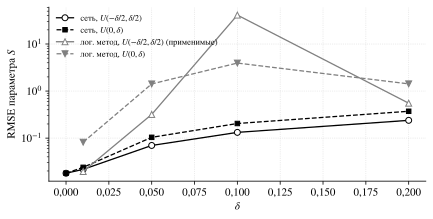

In [42]:
d = tab_noise.index.values
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(d, tab_noise["RMSE S, сеть, центр."], "k-o", mfc="white", label="сеть, $U(-\\delta/2,\\delta/2)$")
ax.plot(d, tab_noise["RMSE S, сеть, U(0,δ)"], "k--s", mfc="black", ms=4.5, label="сеть, $U(0,\\delta)$")
ax.plot(d[1:], tab_noise["RMSE S, лог., центр."].values[1:], color="0.5", ls="-", marker="^",
        mfc="white", label="лог. метод, $U(-\\delta/2,\\delta/2)$ (применимые)")
ax.plot(d[1:], tab_noise["RMSE S, лог., U(0,δ)"].values[1:], color="0.5", ls="--", marker="v",
        mfc="0.5", label="лог. метод, $U(0,\\delta)$")
ax.set_yscale("log"); ax.set_xlabel("$\\delta$"); ax.set_ylabel("RMSE параметра $S$")
ax.legend(fontsize=8.5, loc="upper left"); fig.tight_layout(); savefig(fig, "step7a_noise"); plt.show()

*Рис. Ш7а.* Чувствительность RMSE параметра $S$ к помехе в тестовых сигналах (логарифмический метод показан для $\delta>0$; при $\delta=0$ его ошибка порядка $10^{-15}$).

**Наблюдения.** (1) Смещённая помеха $U(0,\delta)$ вредит сильнее центрированной той же дисперсии: систематический сдвиг всех отсчётов сеть, обученная на чистых данных, интерпретирует как изменение формы. (2) Положительный шум не делает логарифмический метод устойчивым (задача 7 к главе): ошибка логарифма $\approx\varepsilon/y$, поэтому слабые отсчёты на хвостах импульса получают огромные искажения. При центрированной помехе часть отсчётов становится отрицательной, и метод формально неприменим — число таких сигналов указано в таблице. На применимых сигналах RMSE логарифмического метода может достигать десятков единиц: несколько сигналов с почти нулевым $q_2$ дают огромные $S=-1/q_2$. Это типичное проявление неустойчивости обратной задачи — малое возмущение данных вызывает большое изменение решения.

### 7б. Четыре режима обучения и тестирования

Уровень помехи $\delta=0{,}05$. Для «шумного обучения» помеха добавляется один раз к обучающей и валидационной выборкам (валидация повторяет условия обучения); «независимый шумный тест» использует реализацию помехи, не встречавшуюся при обучении.

In [43]:
DLT = 0.05
rng_r = np.random.default_rng(271828)
U_tr, U_va = rng_r.uniform(size=P_tr.shape), rng_r.uniform(size=P_va.shape)
U_te2 = rng_r.uniform(size=P_te.shape)           # независимая от обучения реализация
noise = {"центр.": lambda U: DLT*(U - 0.5), "U(0,δ)": lambda U: DLT*U}

rows = []
for kind, fn in noise.items():
    Ptr_n, Pva_n, Pte_n = P_tr + fn(U_tr), P_va + fn(U_va), P_te + fn(U_te2)
    nrm_n = Normalizer(Ptr_n)
    mdl_n = train(w0, nrm_n.x(Ptr_n), nrm_n.t(T_tr), nrm_n.x(Pva_n), nrm_n.t(T_va))
    mdl_n["norm"] = nrm_n
    for regime, mdl, Pt in [("чистое обуч. / чистый тест", base, P_te),
                            ("чистое обуч. / шумный тест", base, Pte_n),
                            ("шумное обуч. / чистый тест", mdl_n, P_te),
                            ("шумное обуч. / независимый шумный тест", mdl_n, Pte_n)]:
        rm = np.sqrt(np.mean((predict(mdl, Pt) - T_te)**2, axis=1))
        rows.append({"помеха": kind, "режим": regime, "RMSE C": rm[0], "RMSE A": rm[1], "RMSE S": rm[2]})
tab4 = pd.DataFrame(rows).set_index(["помеха", "режим"])

**Вывод.** Обучение на зашумлённых данных — способ сообщить сети условия эксплуатации: модель перестаёт «верить» мелким деталям формы и становится устойчивее к помехе того же типа ценой некоторой потери точности на чистых сигналах.

Обратите внимание на совпадение последних строк двух блоков таблицы. Оно не случайно: смещённая помеха $\delta u$ отличается от центрированной $\delta(u-\tfrac12)$ на **постоянную** $\delta/2$ в каждом канале. При шумном обучении эта постоянная входит в средние $\mu_j$ и вычитается нормировкой (3.37), поэтому сеть получает в точности те же нормированные входы и обучается так же. Если же сдвиг среднего на этапе эксплуатации не совпадает с обучающим (строка «шумное обуч. / чистый тест» для $U(0,\delta)$), нормировка его уже не компенсирует. Инженерный смысл: известное постоянное смещение датчика устраняется калибровкой входов, а не дообучением. Во всех случаях в отчёте необходимо указать, **на каком этапе** и с каким средним добавлялся шум.

> **Перекрёстная связь.** Добавление шума к входам при обучении эквивалентно (в первом приближении) регуляризации, штрафующей чувствительность модели к входу, — тема главы 6. В главе 2 устойчивость порогового нейрона оценивалась запасом потенциала до порога (формула 2.31); здесь та же идея проявляется статистически: насколько сильно возмущение входа меняет выход.

## Шаг 8. Случайные цели: запоминание и обобщение

Входы — 21 независимое число $U(0,1)$, цели $C,A,S$ — независимые $U(0{,}1;\,1)$, **не связанные** со входами. Оптимальный по ожидаемой квадратичной ошибке постоянный прогноз равен $0{,}55$; его популяционная MSE по одной компоненте $0{,}9^2/12=0{,}0675$, RMSE $\approx0{,}25981$.

Чтобы запоминание стало видно, возьмём 100 обучающих примеров (840 параметров против 300 целевых чисел) и 3000 эпох. Будем следить за ошибкой последнего состояния и состояния, отобранного по валидации.

,MSE обуч.,MSE тест
модель,,
"постоянный прогноз 0,55",0.06513,0.06780
"сеть, отбор по валидации (эпоха 19)",0.06230,0.07017
"сеть, последняя эпоха (обуч. / валид.)",0.00000,0.15197


Популяционный ориентир: MSE = 0.0675, RMSE = 0.25981


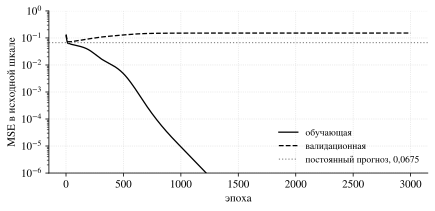

In [44]:
rng_z = np.random.default_rng(161803)
Z = {k: rng_z.uniform(0, 1, size=(21, n)) for k, n in [("tr", 100), ("va", 600), ("te", 600)]}
Y = {k: rng_z.uniform(0.1, 1.0, size=(3, Z[k].shape[1])) for k in Z}
nz = Normalizer(Z["tr"])
mz = train(w0, nz.x(Z["tr"]), nz.t(Y["tr"]), nz.x(Z["va"]), nz.t(Y["va"]), epochs=3000)
mz["norm"] = nz

# Последнее состояние: повторно не обучаем — восстановим кривые в исходной шкале (множитель 0,45^2)
k = 0.45**2
rows = [{"модель": "постоянный прогноз 0,55",
         "MSE обуч.": np.mean((0.55 - Y["tr"])**2), "MSE тест": np.mean((0.55 - Y["te"])**2)},
        {"модель": f"сеть, отбор по валидации (эпоха {mz['best_ep']})",
         "MSE обуч.": np.mean((predict(mz, Z["tr"]) - Y["tr"])**2),
         "MSE тест": np.mean((predict(mz, Z["te"]) - Y["te"])**2)},
        {"модель": "сеть, последняя эпоха (обуч. / валид.)",
         "MSE обуч.": mz["hist_tr"][-1]*k, "MSE тест": mz["hist_va"][-1]*k}]
display(pd.DataFrame(rows).set_index("модель").round(5))
print("Популяционный ориентир: MSE = 0.0675, RMSE = 0.25981")

fig, ax = plt.subplots(figsize=(6.2, 3.1))
e = np.arange(1, 3001)
ax.semilogy(e, mz["hist_tr"]*k, "k-", label="обучающая")
ax.semilogy(e, mz["hist_va"]*k, "k--", label="валидационная")
ax.axhline(0.0675, color="0.55", ls=":", lw=1.2, label="постоянный прогноз, 0,0675")
ax.set_ylim(1e-6, 1); ax.set_xlabel("эпоха"); ax.set_ylabel("MSE в исходной шкале"); ax.legend()
fig.tight_layout(); savefig(fig, "step8_random_targets"); plt.show()

*Рис. Ш8.* Обучение на случайных независимых целях. Обучающая ошибка падает — сеть **запоминает** примеры; валидационная растёт выше уровня постоянного прогноза — закономерности для новых данных нет. Отбор по валидации останавливается вблизи начала обучения, и лучшее, что сеть может сделать, — приблизиться к константе $0{,}55$.

Этот опыт — «отрицательный контроль» эксперимента: если бы на шаге 4 тестовая ошибка была близка к $0{,}26$ по RMSE, это означало бы, что сеть ничего не извлекла из сигналов.

## Шаг 9 (дополнительное задание). Ограниченный нелинейный МНК

Для зашумлённых данных естественный метод сравнения — нелинейный МНК в исходной шкале:
$$
\min_{C,A,S}\ \sum_{j=0}^{20}\Bigl[p_j-C\exp\!\Bigl(-\frac{(x_j-A)^2}{S}\Bigr)\Bigr]^2,\qquad C>0,\ S>0. \tag{3.36}
$$
Известный диапазон параметров $[0{,}1;\,1]$ включаем как ограничения. Начальное приближение: $C$ — максимум отсчётов, $A$ — узел максимума, $S=0{,}5$. Сравниваем с сетью, обученной на центрированном шуме (шаг 7б), на одних и тех же сигналах с $\delta=0{,}05$; время измеряем после «прогрева» вычислений. Время подготовки (обучения сети) указываем отдельно.

In [45]:
from scipy.optimize import least_squares

def nlls_one(p):
    i0 = int(np.argmax(p))
    x0 = np.clip([p.max(), x[i0], 0.5], 0.1, 1.0)
    res = least_squares(lambda th: pulse(x, *th) - p, x0,
                        jac=lambda th: np.column_stack([
                            np.exp(-(x-th[1])**2/th[2]),
                            th[0]*np.exp(-(x-th[1])**2/th[2])*2*(x-th[1])/th[2],
                            th[0]*np.exp(-(x-th[1])**2/th[2])*(x-th[1])**2/th[2]**2]),
                        bounds=([0.1, 0.1, 0.1], [1.0, 1.0, 1.0]), method="trf")
    return res.x

Pn = P_te + DLT*(U_te2 - 0.5)
nrm_c = Normalizer(P_tr + DLT*(U_tr - 0.5))
t0 = time.perf_counter()
mdl_c = train(w0, nrm_c.x(P_tr + DLT*(U_tr - 0.5)), nrm_c.t(T_tr),
              nrm_c.x(P_va + DLT*(U_va - 0.5)), nrm_c.t(T_va))
t_train = time.perf_counter() - t0; mdl_c["norm"] = nrm_c

nlls_one(Pn[:, 0]); predict(mdl_c, Pn[:, :1])                     # прогрев
t0 = time.perf_counter(); est_nl = np.column_stack([nlls_one(Pn[:, i]) for i in range(Pn.shape[1])])
t_nl = time.perf_counter() - t0
t0 = time.perf_counter(); est_nn = predict(mdl_c, Pn); t_nn = time.perf_counter() - t0
est_lg, ok_lg = log_recover(Pn)

rows = []
for name, est, ok in [("сеть (шумное обучение)", est_nn, np.ones(600, bool)),
                      ("нелинейный МНК (3.36)", est_nl, np.ones(600, bool)),
                      ("логарифмический (3.34)–(3.35)", est_lg, ok_lg)]:
    rm = np.sqrt(np.mean((est[:, ok] - T_te[:, ok])**2, axis=1))
    rows.append({"метод": name, "сигналов": int(ok.sum()),
                 "RMSE C": rm[0], "RMSE A": rm[1], "RMSE S": rm[2]})
display(pd.DataFrame(rows).set_index("метод").round(5))
print(f"Подготовка сети: {t_train:.1f} с (однократно)")
print(f"Обработка 600 сигналов: сеть {t_nn*1e3:.2f} мс, нелинейный МНК {t_nl*1e3:.0f} мс "
      f"(≈{t_nl/t_nn:.0f} раз медленнее)")

,сигналов,RMSE C,RMSE A,RMSE S
метод,,,,
сеть (шумное обучение),600,0.01152,0.02427,0.05716
нелинейный МНК (3.36),600,0.00528,0.02094,0.05797
логарифмический (3.34)–(3.35),560,0.03664,0.05209,0.10425


Подготовка сети: 3.2 с (однократно)
Обработка 600 сигналов: сеть 0.49 мс, нелинейный МНК 771 мс (≈1558 раз медленнее)


**Вывод.** Нелинейный МНК использует точную модель сигнала; в этом опыте он заметно точнее сети по $C$, немного точнее по $A$ и сопоставим по $S$ — параметру, который хуже всего определяется данными при любом методе. Но он решает задачу оптимизации **для каждого нового сигнала**. Сеть платит однократным обучением и затем выдаёт оценку за один прямой проход. Логарифмический метод при центрированной помехе неприменим к части сигналов, а на остальных заметно уступает обоим. Практическая ценность метода определяется совокупностью точности, стоимости подготовки, времени обработки и устойчивости к изменению условий — а не одной строкой таблицы.

## Итоги и требования к отчёту

**Что показала работа.**

1. Одна и та же вычислительная структура — линейная комбинация признаков — даёт полином Тейлора, полином МНК, гармоническое приближение и ReLU-сплайн; различаются признаки и способ определения весов (шаг 2).
2. Обратная задача для гауссова импульса идентифицируема: без шума аналитический метод точен до округления. Сеть 21–21–15–3 лишь **приближает** обратное отображение (шаги 3–5).
3. Качество сети зависит от объёма данных, числа шагов оптимизации и выбора архитектуры; выбор делается по валидации, тест используется один раз (шаг 6).
4. Шум, особенно со смещённым средним, ухудшает оценки; шумное обучение повышает устойчивость к помехе того же типа. Логарифмирование неустойчиво к любому шуму (шаг 7).
5. При отсутствии закономерности сеть может только запоминать; ориентир — постоянный прогноз $0{,}55$ (шаг 8).

**Содержание отчёта** (п. 3.4.7): постановка задачи и соглашение о параметре ширины $S$; происхождение данных и правила разделения; архитектура и число параметров; процедура нормировки; настройки обучения и отобранная эпоха; графики ошибки и «эталон — прогноз»; таблицы RMSE, MAE и максимальных ошибок; результаты шумового эксперимента (с указанием этапа добавления шума) и опыта со случайными целями. В выводах сформулировать, для каких сигналов модель достигает выбранного допуска и какие условия вызывают ухудшение. Указать среду и версии, фактически использованные для запуска (первая ячейка тетради).

**Сводная карта связей с другими главами пособия.**

| Идея этой работы | Где она возникала | Где будет развита |
|---|---|---|
| Синтез весов по формуле против обучения по данным | Гл. 2, п. 2.3.8 (логические нейроны) | Гл. 4 (KAN), гл. 11 (PINN) |
| Скрытый слой создаёт признаки | Гл. 2, п. 2.3.6 (XOR) | Гл. 4, 13 (свёрточные признаки) |
| Обратное распространение и Adam | — | Гл. 5 |
| Плохая обусловленность обратной задачи, шум как регуляризация | Гл. 2, п. 2.3.9 (запас до порога) | Гл. 6 (Тихонов) |
| Дискретизация и спектр сигнала | Гл. 3, исторический контекст | Гл. 7, 14 |
| Представление функции суперпозициями (3.31) | Гл. 3, п. 3.3.4 | Гл. 4 |

In [46]:
import platform, scipy
print("Python", platform.python_version(), "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| pandas", pd.__version__, "| Matplotlib", mpl.__version__)
print("Рисунки:", sorted(p.name for p in FIG.glob("*.svg")))

Python 3.10.20 | NumPy 2.2.5 | SciPy 1.15.3 | pandas 2.3.3 | Matplotlib 3.10.9
Рисунки: ['step1_pulses.svg', 'step2a_taylor_vs_lsq.svg', 'step2c_gibbs.svg', 'step4_learning_curve.svg', 'step4_ref_vs_pred.svg', 'step4_worst_cases.svg', 'step5_example.svg', 'step7a_noise.svg', 'step8_random_targets.svg']
